# A leakage-aware classification pipeline

A compact companion to courses 01–02: build a baseline, select regularization using cross-validation, and evaluate once on a held-out test partition.

**Origin:** new study example created with AI assistance during repository curation. It is separate from the IBM lab material. CPU only; no downloads or API calls after environment installation.

**Data:** scikit-learn's bundled Wine dataset (178 observations, 13 features, three classes). This is a small teaching dataset; a favorable score is not evidence of production performance. [Dataset documentation](https://scikit-learn.org/stable/modules/generated/sklearn.datasets.load_wine.html).

[Setup](../docs/SETUP.md) · [Course 01 notes](../courses/01-machine-learning-with-python/README.md)

## 1. Reserve the test partition

The seed, split fraction, scoring rule and parameter grid are specified before fitting. The test labels do not participate in model selection.

In [1]:
import json
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_wine
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import ConfusionMatrixDisplay, accuracy_score, classification_report, f1_score
from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_val_score, train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

SEED = 42
data = load_wine()
train_idx, test_idx = train_test_split(
    np.arange(len(data.target)), test_size=0.25, stratify=data.target, random_state=SEED
)
assert not set(train_idx) & set(test_idx)
X_train, X_test = data.data[train_idx], data.data[test_idx]
y_train, y_test = data.target[train_idx], data.target[test_idx]
print(f"Training: {len(train_idx)}; test: {len(test_idx)}; features: {X_train.shape[1]}")

Matplotlib is building the font cache; this may take a moment.


Training: 133; test: 45; features: 13


## 2. Select the model inside the training partition

StandardScaler is inside the pipeline so every cross-validation fold learns its own training-only statistics. Macro F1 gives each class equal weight. The dummy model provides a simple reference on the same folds.

This example uses seeded SAGA optimization. During environment validation, the initial L-BFGS implementation emitted repeated matrix-multiplication numerical warnings on the local platform. On training-only cross-validation, SAGA produced the same mean macro F1 at C=1 without those warnings. The change addresses the execution behavior rather than selecting a solver from test-set results.

In [2]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
baseline = DummyClassifier(strategy="most_frequent")
baseline_cv = cross_val_score(baseline, X_train, y_train, cv=cv, scoring="f1_macro")
pipeline = make_pipeline(StandardScaler(), LogisticRegression(solver="saga", max_iter=5000, random_state=SEED))
search = GridSearchCV(
    pipeline, {"logisticregression__C": [0.01, 0.1, 1.0, 10.0]},
    cv=cv, scoring="f1_macro", n_jobs=1, refit=True
)
search.fit(X_train, y_train)
print(f"Dummy CV macro F1: {baseline_cv.mean():.3f} ± {baseline_cv.std():.3f}")
print(f"Selected pipeline CV macro F1: {search.best_score_:.3f}")
print("Selected parameters:", search.best_params_)

Dummy CV macro F1: 0.190 ± 0.006
Selected pipeline CV macro F1: 0.985
Selected parameters: {'logisticregression__C': 0.01}


## 3. Evaluate the fixed choice

The test result is a final estimate for this split. Report both accuracy and macro F1, then inspect class-level errors. The assertions below are small deterministic regression checks for this teaching example.

In [3]:
baseline.fit(X_train, y_train)
prediction = search.predict(X_test)
metrics = {
    "dataset": "sklearn-wine",
    "seed": SEED,
    "training_examples": len(train_idx),
    "test_examples": len(test_idx),
    "cv_folds": 5,
    "selected_C": search.best_params_["logisticregression__C"],
    "cv_macro_f1": float(search.best_score_),
    "test_accuracy": float(accuracy_score(y_test, prediction)),
    "test_macro_f1": float(f1_score(y_test, prediction, average="macro")),
    "dummy_test_macro_f1": float(f1_score(y_test, baseline.predict(X_test), average="macro")),
}
assert np.isfinite(list(metrics[key] for key in ["cv_macro_f1", "test_macro_f1"])).all()
assert metrics["test_macro_f1"] > metrics["dummy_test_macro_f1"]
print(classification_report(y_test, prediction, target_names=data.target_names, zero_division=0))
print(json.dumps(metrics, indent=2))

              precision    recall  f1-score   support

     class_0       1.00      1.00      1.00        15
     class_1       1.00      1.00      1.00        18
     class_2       1.00      1.00      1.00        12

    accuracy                           1.00        45
   macro avg       1.00      1.00      1.00        45
weighted avg       1.00      1.00      1.00        45

{
  "dataset": "sklearn-wine",
  "seed": 42,
  "training_examples": 133,
  "test_examples": 45,
  "cv_folds": 5,
  "selected_C": 0.01,
  "cv_macro_f1": 0.9853801169590642,
  "test_accuracy": 1.0,
  "test_macro_f1": 1.0,
  "dummy_test_macro_f1": 0.19047619047619047
}


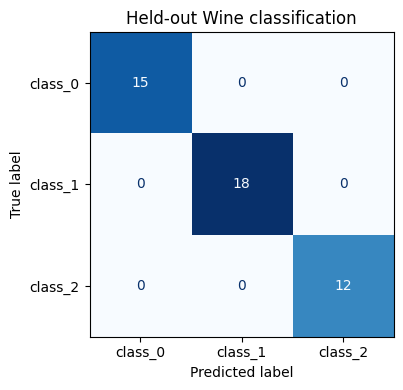

In [4]:
fig, ax = plt.subplots(figsize=(5, 4))
ConfusionMatrixDisplay.from_predictions(
    y_test, prediction, display_labels=data.target_names, cmap="Blues", colorbar=False, ax=ax
)
ax.set_title("Held-out Wine classification")
fig.tight_layout()
plt.show()

## Revisit

Explain why the scaler is inside the pipeline. Then change the feature set using training-only cross-validation; if you use the current test score to make that change, reserve new evaluation data before claiming an unbiased improvement.

A next step is grouped, temporal or external validation when the problem requires it. This notebook makes no claim about deployment or real-world wine authenticity.

In [5]:
# Machine-readable evidence consumed by scripts/run_companions.py.
print("COMPANION_METRICS=" + json.dumps(metrics, sort_keys=True))

COMPANION_METRICS={"cv_folds": 5, "cv_macro_f1": 0.9853801169590642, "dataset": "sklearn-wine", "dummy_test_macro_f1": 0.19047619047619047, "seed": 42, "selected_C": 0.01, "test_accuracy": 1.0, "test_examples": 45, "test_macro_f1": 1.0, "training_examples": 133}
